In [20]:
import pandas as pd
import numpy as np
from sklearn.cluster import KMeans,AgglomerativeClustering
from sklearn.ensemble import RandomForestRegressor,GradientBoostingRegressor
from sklearn.metrics import root_mean_squared_error, r2_score,classification_report,confusion_matrix,mean_absolute_error,precision_recall_curve,accuracy_score,silhouette_score
from sklearn.decomposition import PCA
import seaborn as sns
from sklearn.linear_model import LogisticRegression
import matplotlib.pyplot as plt
import xgboost as xgb
from imblearn.over_sampling import SMOTE
from sklearn.preprocessing import StandardScaler

test_path1=r"C:\Users\kushj\OneDrive\Desktop\Coding\MLCP\CMaps\test_FD001.txt"
test_path2=r"C:\Users\kushj\OneDrive\Desktop\Coding\MLCP\CMaps\test_FD002.txt"
test_path3=r"C:\Users\kushj\OneDrive\Desktop\Coding\MLCP\CMaps\test_FD003.txt"
test_path4=r"C:\Users\kushj\OneDrive\Desktop\Coding\MLCP\CMaps\test_FD004.txt"

train_path1=r"C:\Users\kushj\OneDrive\Desktop\Coding\MLCP\CMaps\train_FD001.txt"
train_path2=r"C:\Users\kushj\OneDrive\Desktop\Coding\MLCP\CMaps\train_FD002.txt"
train_path3=r"C:\Users\kushj\OneDrive\Desktop\Coding\MLCP\CMaps\train_FD003.txt"
train_path4=r"C:\Users\kushj\OneDrive\Desktop\Coding\MLCP\CMaps\train_FD004.txt"

def load_dataset(train_file_path,test_file_path):
    column_names=['unit','time','settings_1','settings_2','settings_3']+[f'sensor_{i}' for i in range(1, 22)]

    train_data_set=pd.read_csv(train_file_path,sep=' ',header=None)
    train_data_set=train_data_set.dropna(axis=1,how='all')
    train_data_set.columns=column_names
    train_data_set['split']='train'


    test_data_set=pd.read_csv(test_file_path,sep=' ',header=None)
    test_data_set=test_data_set.dropna(axis=1,how='all')
    test_data_set.columns=column_names
    test_data_set['split']='test'

    data_set=pd.concat([train_data_set,test_data_set],ignore_index=True)
    
    return data_set

data_set=load_dataset(train_path1,test_path1)

In [21]:
def clustering_kmeans(data):
    data=data.copy()
    sensor_data=data[['time']+[f'sensor_{i}' for i in range(1, 22)]]
    data['degradation_stages']=KMeans(n_clusters=5,random_state=42).fit_predict(sensor_data)

    cluster_means=data.groupby('degradation_stages').mean(numeric_only=True).mean(axis=1)
    sorted_clusters=cluster_means.sort_values().index
    new_clusters={old: new for new, old in enumerate(sorted_clusters)}
    data['degradation_stages']=data['degradation_stages'].map(new_clusters)

    return data

def clustering_agglo(data):
    data=data.copy()
    sensor_data=data[['time']+[f'sensor_{i}' for i in range(1, 22)]]
    data['degradation_stages']=AgglomerativeClustering(n_clusters=5,linkage='ward').fit_predict(sensor_data)

    cluster_means=data.groupby('degradation_stages').mean(numeric_only=True).mean(axis=1)
    sorted_clusters=cluster_means.sort_values().index
    new_clusters={old: new for new, old in enumerate(sorted_clusters)}
    data['degradation_stages']=data['degradation_stages'].map(new_clusters)

    return data


clustered_data_kmeans=clustering_kmeans(data_set)
clustered_data_agglo=clustering_agglo(data_set)

In [22]:
def clustering_model(clustered_data_kmeans,clustered_data_agglo):
    sensor_data1=clustered_data_kmeans[['time']+[f'sensor_{i}' for i in range(1, 22)]]
    sensor_data2=clustered_data_agglo[['time']+[f'sensor_{i}' for i in range(1, 22)]]

    score_kmeans=silhouette_score(sensor_data1,clustered_data_kmeans['degradation_stages'])
    score_agglo=silhouette_score(sensor_data2,clustered_data_agglo['degradation_stages']) 
    
    print(score_kmeans)
    print(score_agglo)

    if score_agglo>score_kmeans:
        return clustered_data_agglo
    else:
        return clustered_data_kmeans

clustered_data=clustering_model(clustered_data_kmeans,clustered_data_agglo)

0.411266011420991
0.3182093846000609


degradation_stages
0    11159
1    10227
2     8315
3     2590
4     1436
Name: count, dtype: int64


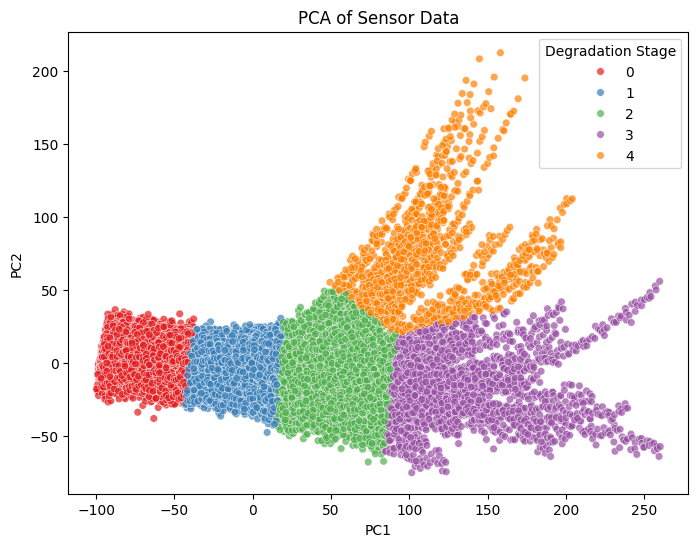

In [23]:
def cluster_count(data):
    print(data['degradation_stages'].value_counts())

def PCA_visualize(data):
    pca=PCA(n_components=2)
    pca_features=pca.fit_transform(data[['time']+[f'sensor_{i}' for i in range(1, 22)]])

    plt.figure(figsize=(8, 6))
    sns.scatterplot(x=pca_features[:, 0],y=pca_features[:, 1],hue=data['degradation_stages'],palette='Set1',s=30,alpha=0.7)
    plt.title('PCA of Sensor Data')
    plt.xlabel('PC1')
    plt.ylabel('PC2')
    plt.legend(title='Degradation Stage')
    plt.show()

cluster_count(clustered_data)
PCA_visualize(clustered_data)

Classification Report:
               precision    recall  f1-score   support

           0       0.99      1.00      1.00      5519
           1       0.99      0.99      0.99      4456
           2       0.99      0.99      0.99      2605
           3       0.99      1.00      0.99       389
           4       0.96      0.96      0.96       127

    accuracy                           0.99     13096
   macro avg       0.99      0.99      0.99     13096
weighted avg       0.99      0.99      0.99     13096



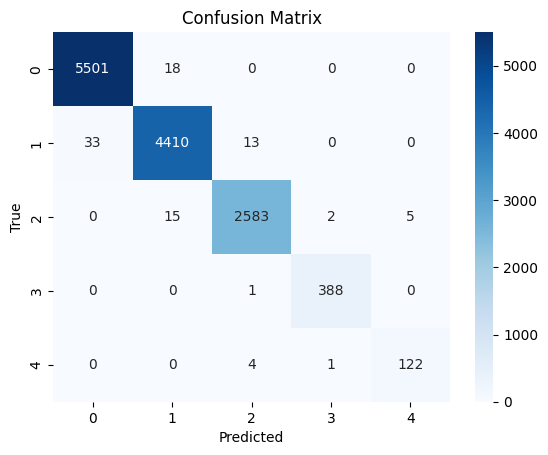

In [24]:
def classsifier_xgboost(data):
    train_data=data[data['split']=='train'].copy()
    test_data=data[data['split']=='test'].copy()

    x_train=train_data[['time']+[f'sensor_{i}' for i in range(1, 22)]]
    y_train=train_data['degradation_stages']
    x_test=test_data[['time']+[f'sensor_{i}' for i in range(1, 22)]]
    y_test=test_data['degradation_stages']
    
    smote=SMOTE(random_state=42)
    x_train_new,y_train_new=smote.fit_resample(x_train,y_train)

    xg_boost=xgb.XGBClassifier(eval_metric="mlogloss")
    xg_boost.fit(x_train_new, y_train_new)

    y_pred=xg_boost.predict(x_test)
    accuracy=accuracy_score(y_test,y_pred)

    print("Classification Report:\n", classification_report(y_test, y_pred))
    sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Blues')
    plt.title('Confusion Matrix')
    plt.xlabel('Predicted')
    plt.ylabel('True')
    plt.show()

    return xg_boost,accuracy

xg_boost,xg_boost_acc=classsifier_xgboost(clustered_data)

Classification Report:
               precision    recall  f1-score   support

           0       0.99      1.00      0.99      5519
           1       0.99      0.99      0.99      4456
           2       0.99      0.98      0.99      2605
           3       0.97      1.00      0.99       389
           4       0.90      0.96      0.93       127

    accuracy                           0.99     13096
   macro avg       0.97      0.98      0.98     13096
weighted avg       0.99      0.99      0.99     13096



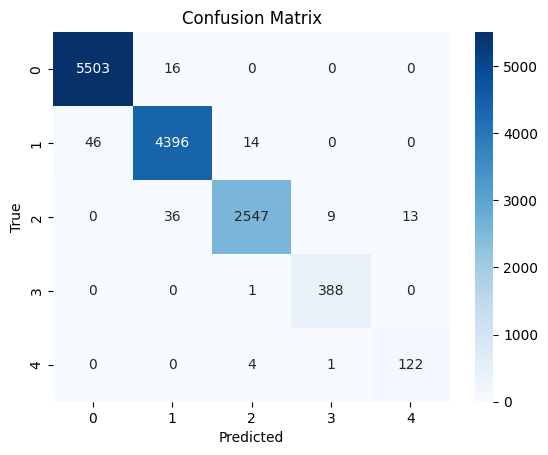

In [25]:
def classsifier_logistic_reg(data):
    train_data=data[data['split']=='train'].copy()
    test_data=data[data['split']=='test'].copy()

    x_train=train_data[['time']+[f'sensor_{i}' for i in range(1, 22)]]
    y_train=train_data['degradation_stages']
    x_test=test_data[['time']+[f'sensor_{i}' for i in range(1, 22)]]
    y_test=test_data['degradation_stages']

    scaler=StandardScaler()
    x_train_scaled=scaler.fit_transform(x_train)
    x_test_scaled=scaler.transform(x_test)
    
    smote=SMOTE(random_state=42)
    x_train_new,y_train_new=smote.fit_resample(x_train_scaled,y_train)

    logistic_reg=LogisticRegression(class_weight='balanced',max_iter=1000,solver='lbfgs')
    logistic_reg.fit(x_train_new, y_train_new)

    y_pred=logistic_reg.predict(x_test_scaled)
    accuracy=accuracy_score(y_test,y_pred)
    
    print("Classification Report:\n", classification_report(y_test, y_pred))
    sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Blues')
    plt.title('Confusion Matrix')
    plt.xlabel('Predicted')
    plt.ylabel('True')
    plt.show()

    return logistic_reg,accuracy

logistic_reg,logistic_reg_acc=classsifier_logistic_reg(clustered_data)

In [26]:
def classification_model(xg_boost,logistic_reg,xg_boost_acc,logistic_reg_acc):

    print(xg_boost_acc)
    print(logistic_reg_acc)

    if logistic_reg_acc>xg_boost_acc:
        return logistic_reg
    else:
        return xg_boost

classify_model=classification_model(xg_boost,logistic_reg,xg_boost_acc,logistic_reg_acc)

0.9929749541844838
0.9893097128894319


In [27]:
def time_prediction(data):
    data=data.copy()
    data['remaining_time'] = np.nan
    for each_unit in data['unit'].unique():
        unit_data=data[data['unit'] == each_unit]
        for stage in range(4):
            curr_stage_data=unit_data[unit_data['degradation_stages']==stage]
            next_stage_data=unit_data[unit_data['degradation_stages']==stage+1]
            if next_stage_data.empty:
                continue
            for idx, row in curr_stage_data.iterrows():
                curr_time=row['time']
                next_time=next_stage_data[next_stage_data['time']>curr_time]['time']
                if not next_time.empty:
                    least_next_time=next_time.min()
                    data.loc[idx,'remaining_time']=least_next_time-curr_time

    return data.dropna(subset=['remaining_time'])

def predict(data):
    train_data=data[data['split']=='train'].copy()
    test_data=data[data['split']=='test'].copy()

    train_time_data=time_prediction(train_data)
    test_time_data=time_prediction(test_data)

    data_set=pd.concat([train_time_data,test_time_data],ignore_index=True)
    return data_set 

time_data=predict(clustered_data)

In [28]:
def regressor_randomforest(data):
    train_data=data[data['split']=='train'].copy()
    test_data=data[data['split']=='test'].copy()

    x_train=train_data[['time','settings_1','settings_2','settings_3']+[f'sensor_{i}' for i in range(1, 22)]]
    y_train=train_data['remaining_time']

    x_test=test_data[['time','settings_1','settings_2','settings_3']+[f'sensor_{i}' for i in range(1, 22)]]
    y_test=test_data['remaining_time']

    random_forest=RandomForestRegressor(random_state=42)

    random_forest.fit(x_train,y_train)
    y_pred=random_forest.predict(x_test)

    print("Random Forest:")
    print(f"RMSE: {root_mean_squared_error(y_test, y_pred):.2f}")
    print(f"MAE: {mean_absolute_error(y_test, y_pred):.2f}")
    print(f"R^2 Score: {r2_score(y_test, y_pred):.2f}\n")

    return random_forest,r2_score(y_test,y_pred)

random_forest,rf_accuracy=regressor_randomforest(time_data)

Random Forest:
RMSE: 3.36
MAE: 0.86
R^2 Score: 0.96



In [29]:
def regressor_gradBoost(data):
    train_data=data[data['split']=='train'].copy()
    test_data=data[data['split']=='test'].copy()

    x_train=train_data[['time','settings_1','settings_2','settings_3']+[f'sensor_{i}' for i in range(1, 22)]]
    y_train=train_data['remaining_time']

    x_test=test_data[['time','settings_1','settings_2','settings_3']+[f'sensor_{i}' for i in range(1, 22)]]
    y_test=test_data['remaining_time']

    grad_boost_reg=GradientBoostingRegressor(loss='squared_error',n_estimators=200,learning_rate=0.1,max_depth=10,random_state=42)

    grad_boost_reg.fit(x_train,y_train)
    y_pred=grad_boost_reg.predict(x_test)

    print("Gradient Boosting Regression:")
    print(f"RMSE: {root_mean_squared_error(y_test, y_pred):.2f}")
    print(f"MAE: {mean_absolute_error(y_test, y_pred):.2f}")
    print(f"R^2 Score: {r2_score(y_test, y_pred):.2f}\n")

    return grad_boost_reg,r2_score(y_test,y_pred)

grad_boost_reg,grad_accuracy=regressor_gradBoost(time_data)

Gradient Boosting Regression:
RMSE: 3.14
MAE: 0.80
R^2 Score: 0.97



In [30]:
def regression_model(random_forest,grad_boost_reg,grad_accuracy,rf_accuracy):
    if grad_accuracy>rf_accuracy:
        return grad_boost_reg
    else:
        return random_forest
    
reg_model=regression_model(random_forest,grad_boost_reg,grad_accuracy,rf_accuracy)


In [31]:
def risk_score(classify_model,reg_model,clustered_data):
    data=clustered_data[clustered_data['split']=='train'].copy()
    proba=classify_model.predict_proba(data[['time']+[f'sensor_{i}' for i in range(1, 22)]])
    failure_proba=proba[:, 4]
    
    time_left=reg_model.predict(data[['time','settings_1','settings_2','settings_3']+[f'sensor_{i}' for i in range(1, 22)]])
    raw_score=failure_proba/(time_left+1e-6)
    norm_score=(raw_score-raw_score.min())/(raw_score.max()-raw_score.min())
    data['risk_score']=norm_score

    return data[['unit','time','degradation_stages','risk_score']]

risk_data=risk_score(classify_model,reg_model,clustered_data)

In [32]:
def maintenance_alert(data):
    data['alert']=data['risk_score']>0.01
    alert_data=data[data['alert']==True]
    if len(alert_data)>0:
        print("⚠️ Maintenance Alert!")
        print(alert_data[['unit','time']])

def tune_threshold(data):
    y_true=(data['degradation_stages']==4).astype(int)  
    y_pred=data['risk_score']
    precision,recall,thresholds=precision_recall_curve(y_true,y_pred)
    f1_scores=2*(precision*recall)/(precision+recall)

    best_threshold=thresholds[np.argmax(f1_scores)]
    print(f"Best threshold for maintenance alert: {best_threshold:.2f}")
    
    return best_threshold

maintenance_alert(risk_data)
tune_threshold(risk_data)

⚠️ Maintenance Alert!
       unit  time
631       3   153
632       3   154
633       3   155
634       3   156
635       3   157
...     ...   ...
20085    97   198
20086    97   199
20087    97   200
20088    97   201
20089    97   202

[1260 rows x 2 columns]
Best threshold for maintenance alert: 0.01


np.float64(0.007319670986818964)

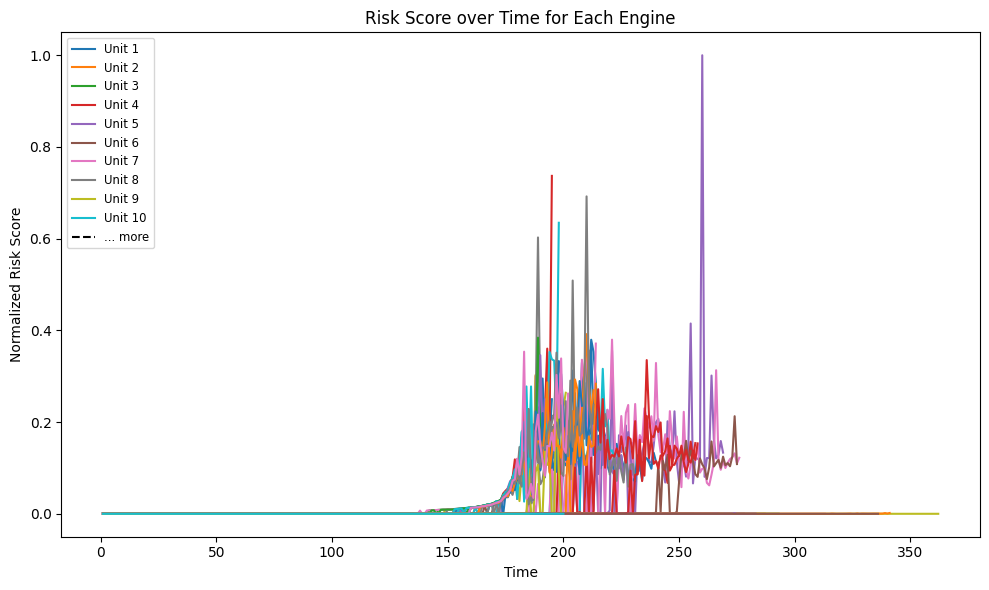

In [33]:
def plot_risk_score(data, max_labels=10):
    plt.figure(figsize=(10, 6))
    unique_units=data['unit'].unique()
    
    for unit in unique_units:
        unit_data=data[data['unit'] == unit]
        grouped = unit_data.groupby('time')['risk_score'].max().reset_index()

        plt.plot(grouped['time'], grouped['risk_score'], label=f'Unit {unit}')

    plt.title('Risk Score over Time for Each Engine')
    plt.xlabel('Time')
    plt.ylabel('Normalized Risk Score')
    
    handles, labels=plt.gca().get_legend_handles_labels()
    shown_handles=handles[:max_labels]
    shown_labels=labels[:max_labels]
    
    if len(labels)>max_labels:
        shown_handles.append(plt.Line2D([],[],color='black',linestyle='--'))
        shown_labels.append('... more')

    plt.legend(shown_handles,shown_labels,loc='upper left',fontsize='small')
    plt.tight_layout()
    plt.show()

plot_risk_score(risk_data)

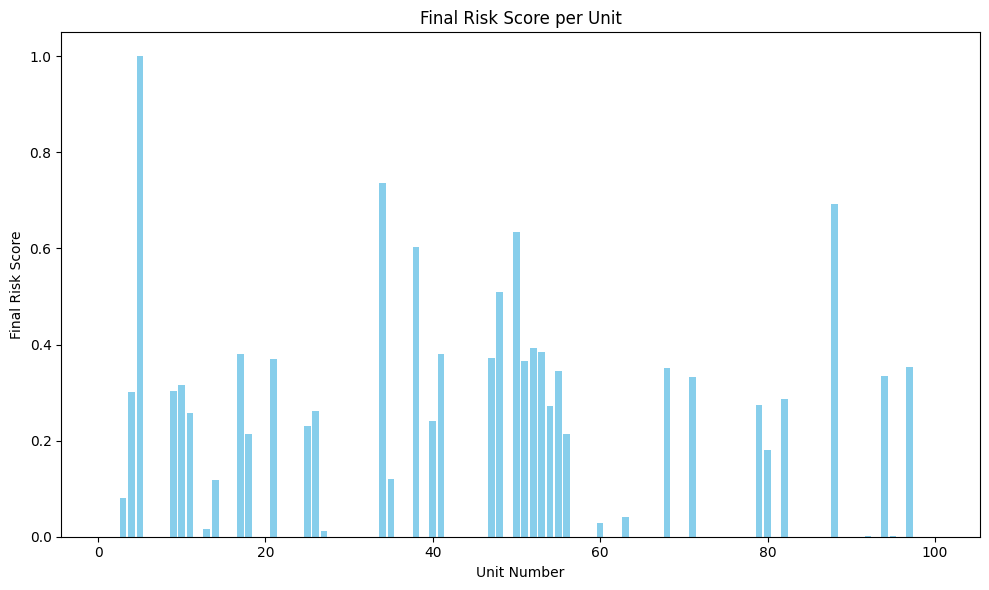

In [34]:
def plot_risk_score_vs_unit(data):
    final_scores = data.groupby('unit')['risk_score'].max().reset_index()

    plt.figure(figsize=(10, 6))
    plt.bar(final_scores['unit'], final_scores['risk_score'], color='skyblue')
    plt.xlabel('Unit Number')
    plt.ylabel('Final Risk Score')
    plt.title('Final Risk Score per Unit')
    plt.tight_layout()
    plt.show()

plot_risk_score_vs_unit(risk_data)

In [35]:
def combine_dataset(path1,path2):
    column_names=['unit','time','settings_1','settings_2','settings_3']+[f'sensor_{i}' for i in range(1, 22)]

    data_1=pd.read_csv(path1,sep=' ',header=None)
    data_1=data_1.dropna(axis=1,how='all')
    data_1.columns=column_names

    data_2=pd.read_csv(path2,sep=' ',header=None)
    data_2=data_2.dropna(axis=1,how='all')
    data_2.columns=column_names

    data_set=pd.concat([data_2,data_1],ignore_index=True)
    
    return data_set

def load_combined_dataset(data_set1,data_set2):

    data_set1['split']='train'
    data_set2['split']='test'

    data_set=pd.concat([data_set2,data_set1],ignore_index=True)
    
    return data_set

degradation_stages
0    23223
1    21610
2    17675
3     9533
4     3002
Name: count, dtype: int64


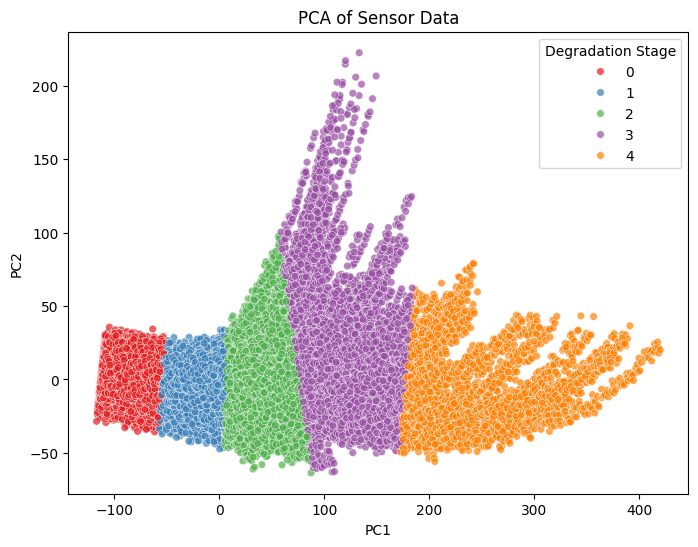

Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00     11517
           1       0.99      0.99      0.99      9540
           2       0.99      0.99      0.99      5750
           3       0.99      1.00      0.99      2187
           4       1.00      1.00      1.00       698

    accuracy                           0.99     29692
   macro avg       0.99      1.00      0.99     29692
weighted avg       0.99      0.99      0.99     29692



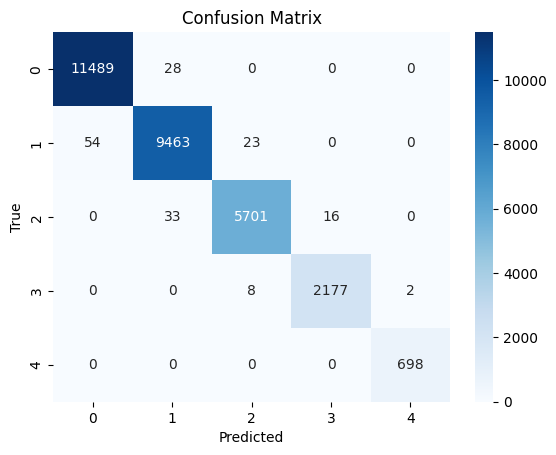

Classification Report:
               precision    recall  f1-score   support

           0       0.99      1.00      0.99      5519
           1       0.99      0.99      0.99      4456
           2       0.99      0.98      0.99      2605
           3       0.97      1.00      0.99       389
           4       0.90      0.96      0.93       127

    accuracy                           0.99     13096
   macro avg       0.97      0.98      0.98     13096
weighted avg       0.99      0.99      0.99     13096



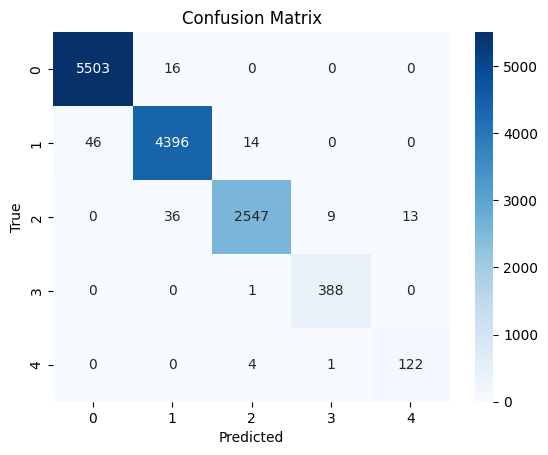

0.9944766267007948
0.9893097128894319
Random Forest:
RMSE: 5.21
MAE: 2.17
R^2 Score: 0.92

Gradient Boosting Regression:
RMSE: 5.39
MAE: 2.27
R^2 Score: 0.92

⚠️ Maintenance Alert!
       unit  time
31477     7   289
31478     7   290
31479     7   291
31480     7   292
31481     7   293
...     ...   ...
74295    96   332
74296    96   333
74297    96   334
74298    96   335
74299    96   336

[2310 rows x 2 columns]
Best threshold for maintenance alert: 0.59


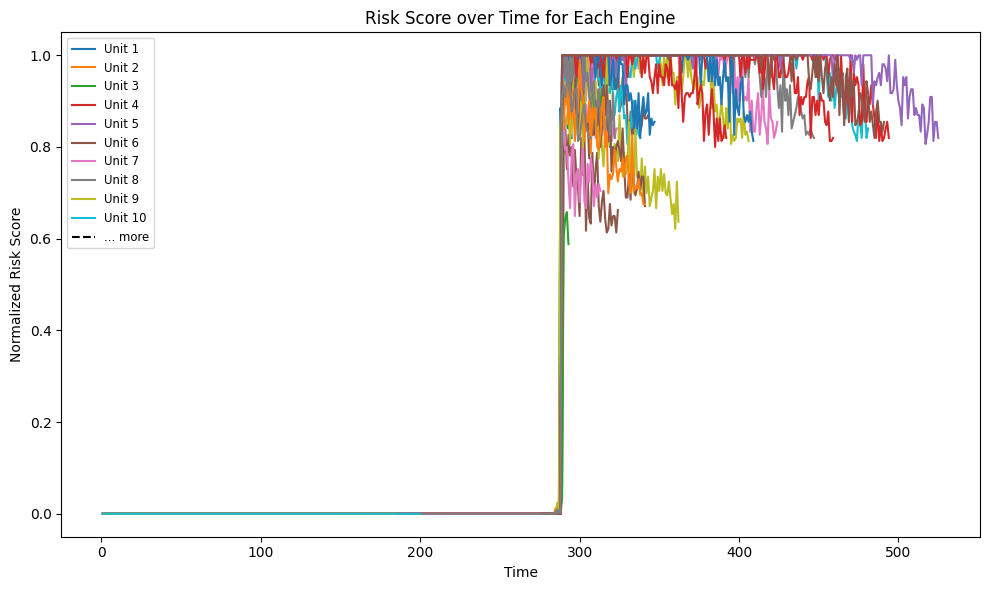

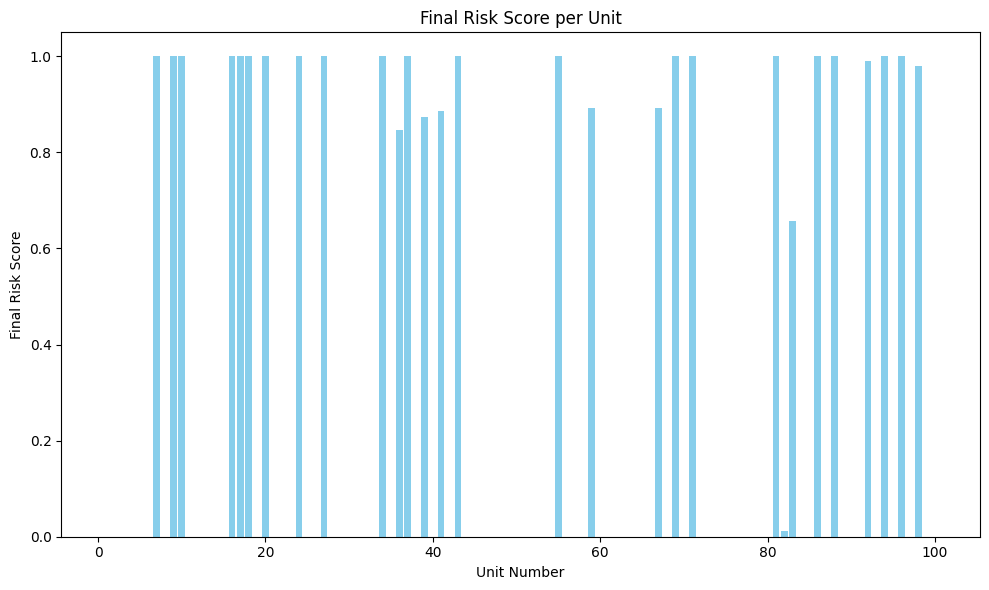

In [36]:
train_data_1=combine_dataset(train_path1,train_path3)
test_data_1=combine_dataset(test_path1,test_path3)
combined_data_1=load_combined_dataset(train_data_1,test_data_1)

clustered_data1=clustering_kmeans(combined_data_1)

cluster_count(clustered_data1)
PCA_visualize(clustered_data1)

xg_boost,xg_boost_acc=classsifier_xgboost(clustered_data1)
logistic_reg,logistic_reg_acc=classsifier_logistic_reg(clustered_data)
classify_model=classification_model(xg_boost,logistic_reg,xg_boost_acc,logistic_reg_acc)

time_data=predict(clustered_data1)
random_forest,rf_accuracy=regressor_randomforest(time_data)
grad_boost_reg,grad_accuracy=regressor_gradBoost(time_data)
reg_model=regression_model(random_forest,grad_boost_reg,grad_accuracy,rf_accuracy)

risk_data=risk_score(classify_model,reg_model,clustered_data1)
maintenance_alert(risk_data)
tune_threshold(risk_data)
plot_risk_score(risk_data)
plot_risk_score_vs_unit(risk_data)

degradation_stages
3    57142
1    49682
4    28484
0    28290
2    26615
Name: count, dtype: int64


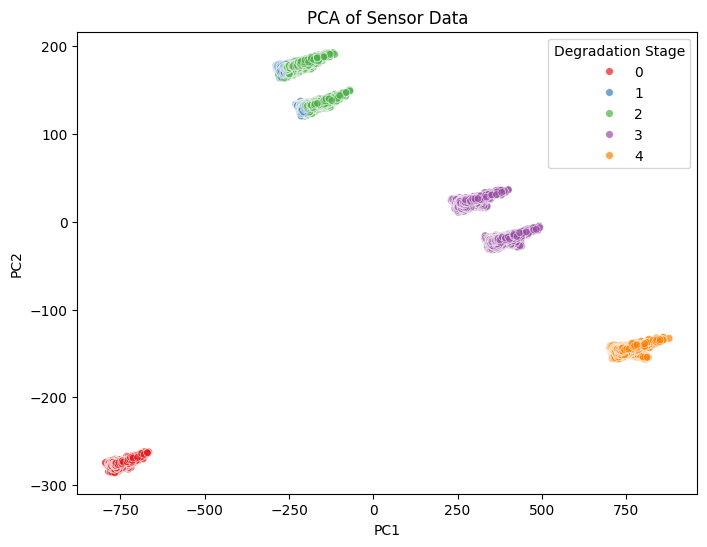

Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00     11149
           1       1.00      1.00      1.00     22418
           2       1.00      1.00      1.00      7827
           3       1.00      1.00      1.00     22609
           4       1.00      1.00      1.00     11202

    accuracy                           1.00     75205
   macro avg       1.00      1.00      1.00     75205
weighted avg       1.00      1.00      1.00     75205



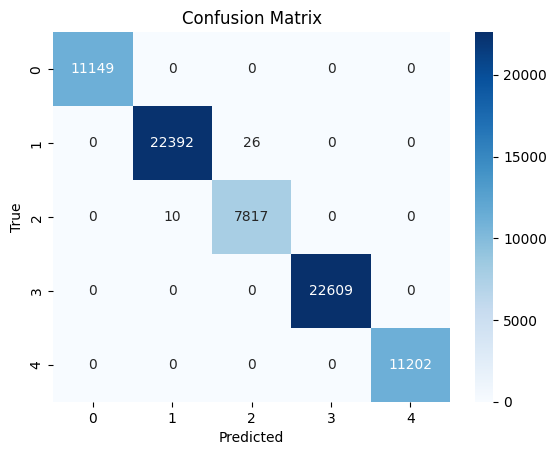

Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00     11149
           1       1.00      1.00      1.00     22418
           2       0.99      1.00      1.00      7827
           3       1.00      1.00      1.00     22609
           4       1.00      1.00      1.00     11202

    accuracy                           1.00     75205
   macro avg       1.00      1.00      1.00     75205
weighted avg       1.00      1.00      1.00     75205



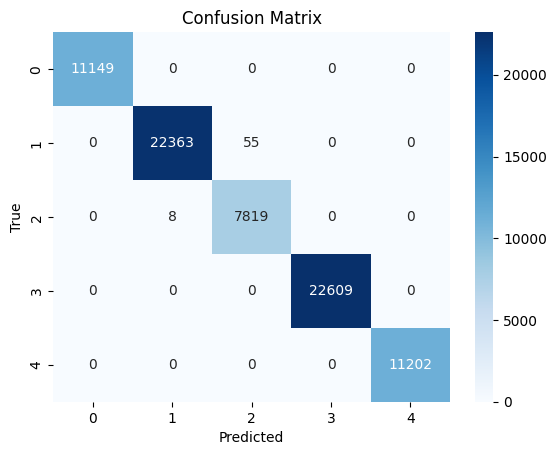

0.9995213084236421
0.9991622897413736
Random Forest:
RMSE: 3.30
MAE: 2.27
R^2 Score: 0.99

Gradient Boosting Regression:
RMSE: 3.32
MAE: 2.26
R^2 Score: 0.99

0.9925699648233969
0.9924811962393287
⚠️ Maintenance Alert!
        unit  time
75211      1     7
75225      1    21
75227      1    23
75232      1    28
75242      1    38
...      ...   ...
190198   260   302
190199   260   303
190202   260   306
190203   260   307
190207   260   311

[17282 rows x 2 columns]
Best threshold for maintenance alert: 0.53


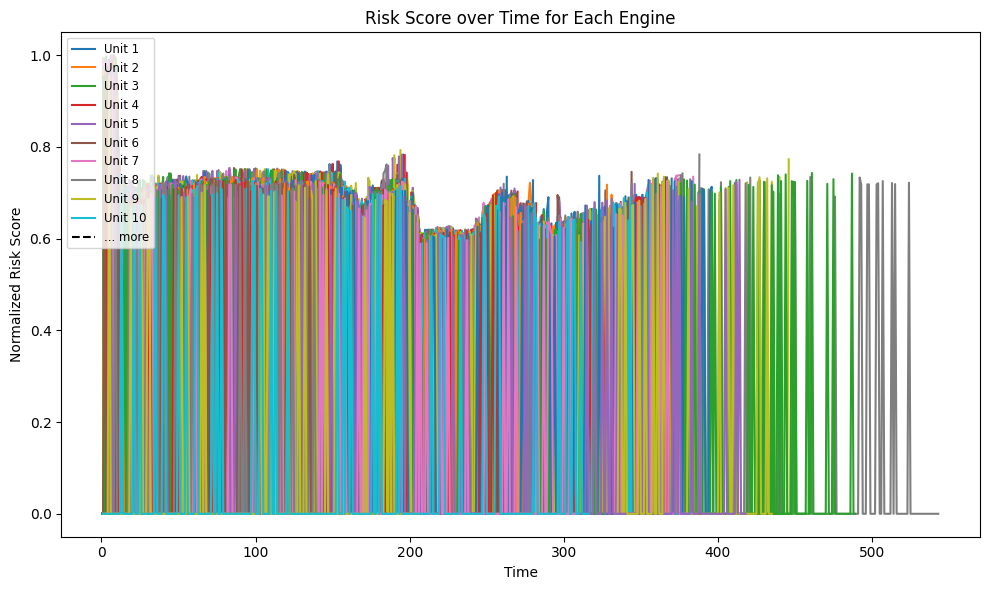

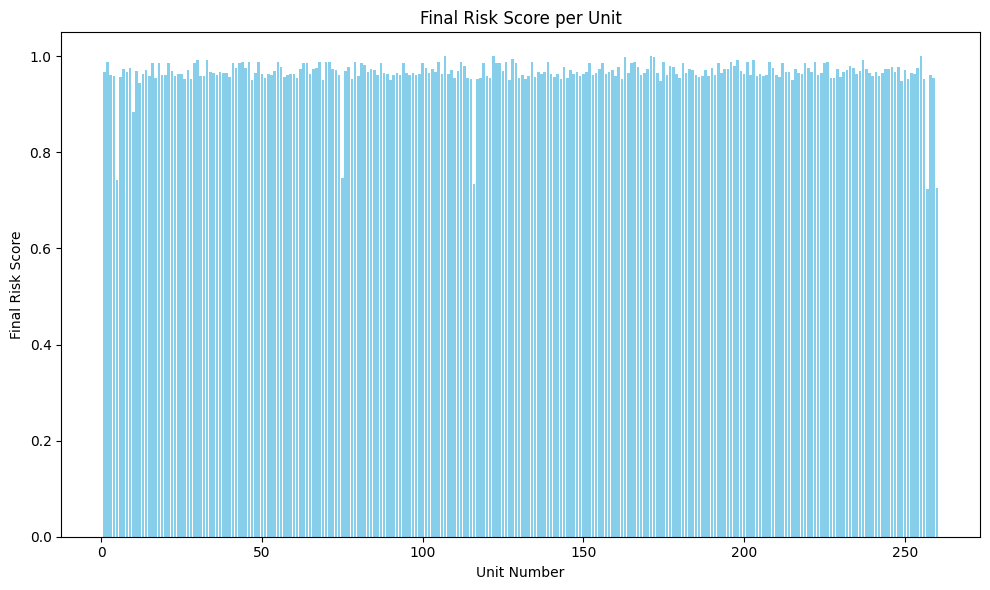

In [39]:
train_data_2=combine_dataset(train_path2,train_path4)
test_data_2=combine_dataset(test_path2,test_path4)
combined_data_2=load_combined_dataset(train_data_2,test_data_2)

clustered_data2=clustering_kmeans(combined_data_2)

cluster_count(clustered_data2)
PCA_visualize(clustered_data2)

xg_boost,xg_boost_acc=classsifier_xgboost(clustered_data2)
logistic_reg,logistic_reg_acc=classsifier_logistic_reg(clustered_data2)
classify_model=classification_model(xg_boost,logistic_reg,xg_boost_acc,logistic_reg_acc)

time_data=predict(clustered_data2)
random_forest,rf_accuracy=regressor_randomforest(time_data)
grad_boost_reg,grad_accuracy=regressor_gradBoost(time_data)
print(rf_accuracy)
print(grad_accuracy)
reg_model=regression_model(random_forest,grad_boost_reg,grad_accuracy,rf_accuracy)

risk_data=risk_score(classify_model,reg_model,clustered_data2)
maintenance_alert(risk_data)
tune_threshold(risk_data)
plot_risk_score(risk_data)
plot_risk_score_vs_unit(risk_data)

degradation_stages
4    103527
1     76297
2     37282
0     28290
3     19860
Name: count, dtype: int64


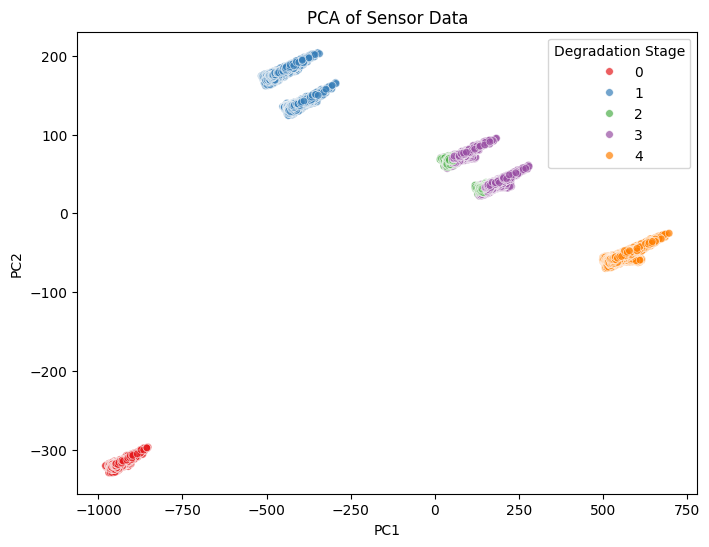

Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00     11149
           1       1.00      1.00      1.00     30245
           2       1.00      1.00      1.00     16764
           3       0.99      1.00      1.00      5845
           4       1.00      1.00      1.00     40894

    accuracy                           1.00    104897
   macro avg       1.00      1.00      1.00    104897
weighted avg       1.00      1.00      1.00    104897



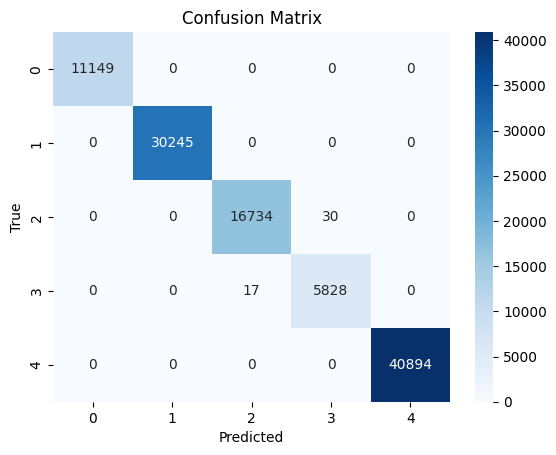

Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00     11149
           1       1.00      1.00      1.00     30245
           2       1.00      1.00      1.00     16764
           3       0.99      1.00      1.00      5845
           4       1.00      1.00      1.00     40894

    accuracy                           1.00    104897
   macro avg       1.00      1.00      1.00    104897
weighted avg       1.00      1.00      1.00    104897



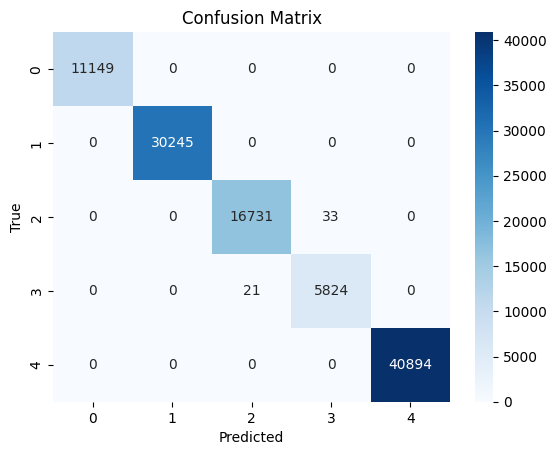

0.9995519414282582
0.999485209300552
Random Forest:
RMSE: 3.92
MAE: 2.25
R^2 Score: 0.98

Gradient Boosting Regression:
RMSE: 3.94
MAE: 2.24
R^2 Score: 0.98

⚠️ Maintenance Alert!
        unit  time
104897     1     1
104898     1     2
104899     1     3
104900     1     4
104901     1     5
...      ...   ...
265241   260   302
265242   260   303
265245   260   306
265246   260   307
265250   260   311

[62633 rows x 2 columns]
Best threshold for maintenance alert: 0.03


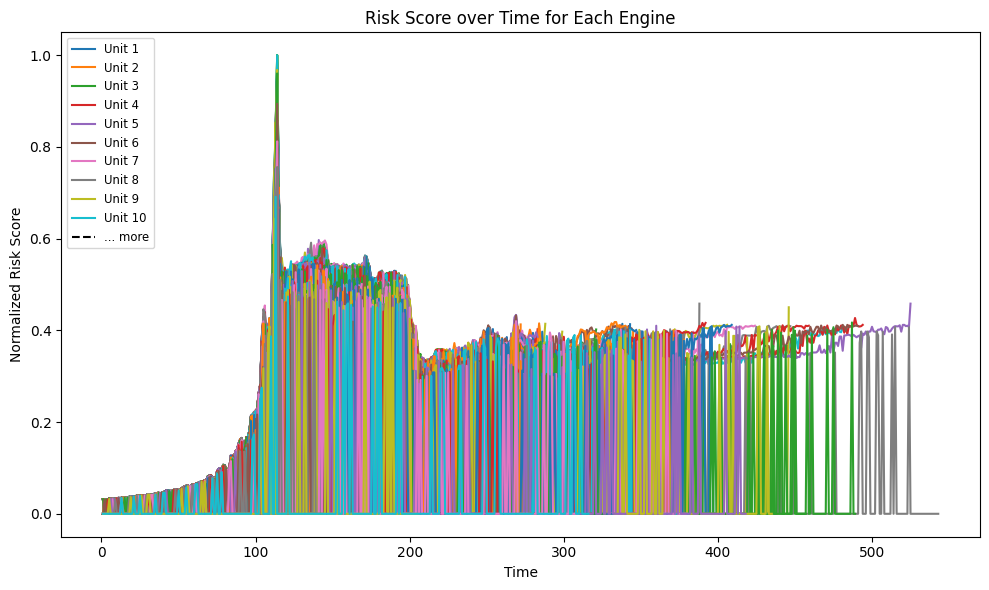

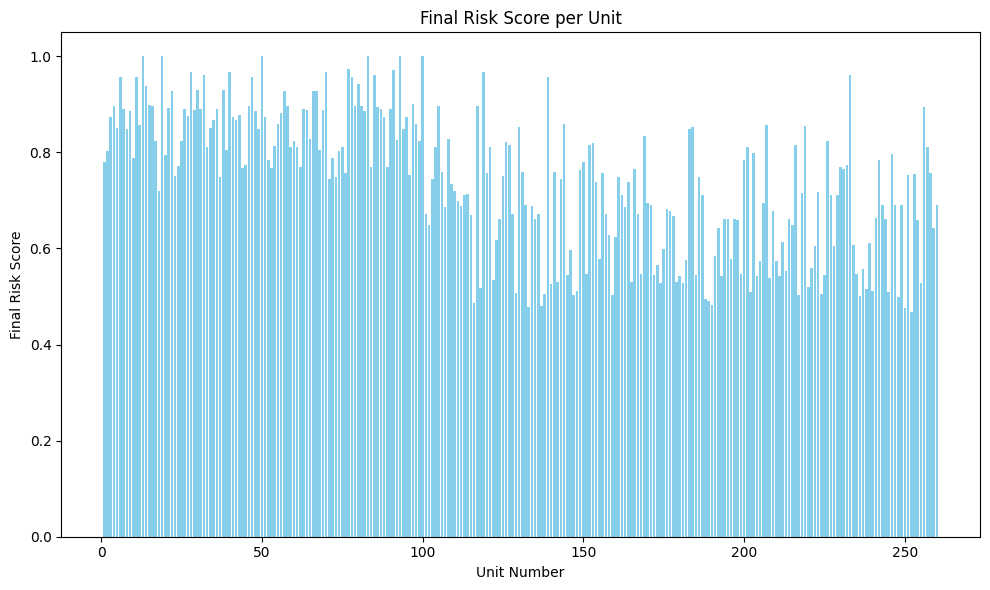

In [ ]:
train_data_3=pd.concat([train_data_1,train_data_2],ignore_index=True)
test_data_3=pd.concat([test_data_1,test_data_2],ignore_index=True)
combined_data_3=load_combined_dataset(train_data_3,test_data_3)

clustered_data3=clustering_kmeans(combined_data_3)

cluster_count(clustered_data3)
PCA_visualize(clustered_data3)

xg_boost,xg_boost_acc=classsifier_xgboost(clustered_data3)
logistic_reg,logistic_reg_acc=classsifier_logistic_reg(clustered_data3)
classify_model=classification_model(xg_boost,logistic_reg,xg_boost_acc,logistic_reg_acc)

time_data=predict(clustered_data3)
random_forest,rf_accuracy=regressor_randomforest(time_data)
grad_boost_reg,grad_accuracy=regressor_gradBoost(time_data)
reg_model=regression_model(random_forest,grad_boost_reg,grad_accuracy,rf_accuracy)

risk_data=risk_score(classify_model,reg_model,clustered_data3)
maintenance_alert(risk_data)
tune_threshold(risk_data)
plot_risk_score(risk_data)
plot_risk_score_vs_unit(risk_data)